# Clusters de comportamiento de mercado del suelo

Los notebooks anteriores preguntaban *cuánto vale* y *cuánto va a valer*. Este
pregunta otra cosa: **¿cuántas maneras distintas de comportarse tiene el suelo
de Bogotá, y cuáles de ellas destacan?**

## La decisión de diseño que lo define todo

Los clusters se construyen **solo con el comportamiento de mercado** de cada
manzana: su precio, cómo se ha movido en diez años, qué tan errático ha sido ese
movimiento y qué dice el pronóstico. La ubicación, la morfología construida y el
uso económico **no entran** en el agrupamiento.

No es una omisión, es el punto. Si se mete la ubicación, los clusters salen
geográficos por construcción y después no se puede afirmar nada: decir "este
grupo está en el norte y es caro" sería circular. Dejándola fuera, la geografía
queda como **validación externa**, y la pregunta "¿los grupos que el algoritmo
encontró por su comportamiento coinciden con zonas reconocibles de la ciudad?"
pasa a tener una respuesta que significa algo.

| | Entra al clustering | Se usa solo para interpretar |
|---|---|---|
| Precio 2026, valorización, volatilidad, inercia, pronóstico | ✔ | |
| Longitud, latitud, distancias, vecinos | | ✔ |
| IVS y morfología construida | | ✔ |
| Uso económico predominante | | ✔ |
| Sector catastral | | ✔ |

## Qué contiene

1. **Ocho variables de comportamiento** y su diagnóstico de colinealidad.
2. **¿Hay algo que agrupar?** El estadístico de Hopkins antes de agrupar nada.
3. **Elección de k con cinco criterios**, incluida la **estabilidad por
   remuestreo**, que es la que de verdad distingue una estructura real de una
   partición arbitraria.
4. **Seis algoritmos**: K-Means, mezcla gaussiana, jerárquico de Ward, BIRCH,
   DBSCAN y una variante **espacialmente contigua**.
5. **Rejillas de hiperparámetros** por algoritmo: tipo de covarianza y BIC/AIC,
   eps y min_samples, tipo de enlace.
6. **Las zonas que destacan**, en dos sentidos: las de **oportunidad** (crecen
   más de lo que su precio haría esperar) y las **atípicas** (no se parecen a
   nada).

**Requisito**: haber ejecutado `notebooks/pronostico_valor_suelo.ipynb`, que deja
`data/processed/pronostico_manzanas.csv.gz` y la caché de Catastro.

## 0. Preparación

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

import unicodedata

from scipy.cluster.hierarchy import dendrogram, linkage as scipy_linkage
from sklearn.cluster import (DBSCAN, Birch, AgglomerativeClustering, KMeans,
                             MiniBatchKMeans)
from sklearn.decomposition import PCA
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_score)
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors, kneighbors_graph
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
%matplotlib inline

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import config as C

print("raiz del proyecto:", ROOT)

raiz del proyecto: C:\Users\Usuario\Proyectos\Catastro_ML


### Parámetros editables

In [2]:
# --- datos -----------------------------------------------------------------
ANIO_INI, ANIO_FIN = 2017, 2026
ANIO_RECIENTE = 2023          # inicio del tramo "reciente"

# --- clustering ------------------------------------------------------------
K_RANGO = range(2, 13)        # valores de k que se barren
K_ELEGIDO = None              # None = lo decide el analisis de la seccion 3
SEMILLA = C.SEED
N_SUBMUESTRA = 6000           # para el jerarquico libre y la silueta (O(n^2))
N_BOOTSTRAP_ARI = 15          # repeticiones del test de estabilidad
K_VECINOS_ESPACIAL = 8        # conectividad para la variante contigua

# --- rejillas de hiperparametros -------------------------------------------
COVARIANZAS_GMM = ["full", "tied", "diag", "spherical"]
ENLACES = ["ward", "complete", "average"]
DBSCAN_EPS = [0.3, 0.5, 0.7, 1.0]
DBSCAN_MIN = [25, 50]

# --- "destacar" ------------------------------------------------------------
PCT_ATIPICAS = 1.0            # percentil inferior de verosimilitud que se marca

GUARDAR_TABLAS = True
GUARDAR_FIGURAS = False

F_VREF = C.PROC_DIR / "catastro_valor_referencia.csv.gz"
F_USO = C.PROC_DIR / "catastro_uso_predominante.csv.gz"
F_PRONOSTICO = C.PROC_DIR / "pronostico_manzanas.csv.gz"
F_SALIDA = C.PROC_DIR / "clusters_manzanas.csv.gz"

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 96, "savefig.dpi": 130, "savefig.bbox": "tight",
                     "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold"})
AZUL, VERDE, NARANJA, ROJO, AMARILLO, GRIS = "#264653", "#2a9d8f", "#f4a261", "#e76f51", "#e9c46a", "#9aa5ab"
PALETA = ["#264653", "#2a9d8f", "#e9c46a", "#f4a261", "#e76f51", "#7b2cbf",
          "#0077b6", "#06d6a0", "#bc6c25", "#8d99ae", "#d62828", "#3a5a40"]
ASPECTO = 1 / np.cos(np.radians(4.65))

rng = np.random.default_rng(SEMILLA)

def guardar_fig(fig, archivo):
    if GUARDAR_FIGURAS:
        fig.savefig(C.FIG_DIR / archivo, facecolor="white")

def guardar_tabla(tabla, archivo, **kw):
    if GUARDAR_TABLAS:
        tabla.to_csv(C.TAB_DIR / archivo, **kw)

def formato_mapa(ax, titulo=None):
    ax.set_xlim(*C.URB_LON); ax.set_ylim(*C.URB_LAT)
    ax.set_aspect(ASPECTO); ax.set_xlabel("longitud"); ax.grid(alpha=.25)
    if titulo:
        ax.set_title(titulo)

def pesos(x, pos=None):
    return "%.1f M" % (x / 1e6) if x >= 1e6 else "%.0f k" % (x / 1e3)

def pct(x):
    "Pasa un crecimiento anual en log10 a porcentaje anual."
    return 100 * (10 ** x - 1)

print("barrido de k: %d a %d | submuestra para O(n^2): %d | semilla %d"
      % (min(K_RANGO), max(K_RANGO), N_SUBMUESTRA, SEMILLA))

barrido de k: 2 a 12 | submuestra para O(n^2): 6000 | semilla 42


## 1. Las ocho variables de comportamiento

Cada manzana queda descrita por su propia serie de precios y nada más. Las
variables están pensadas para capturar cosas distintas: dónde está parada
(`nivel`), hacia dónde va (`cagr_total`, `cagr_reciente`), si cambió de marcha
(`aceleracion`), qué tan errática es (`volatilidad`, `salto_max`), qué tan
quieta la tiene Catastro (`inercia`) y qué dice el modelo del notebook anterior
(`pron_relativo`).

In [3]:
vref = pd.read_csv(F_VREF, dtype={"MANCODIGO": str})
vref["anio"] = pd.to_datetime(vref["ANO"], unit="ms").dt.year
vref = (vref.rename(columns={"MANCODIGO": "manzana", "V_REF": "cop_m2"})
        .query("cop_m2 > 0")
        .groupby(["manzana", "anio"], as_index=False)["cop_m2"].median())
ancha = vref.pivot(index="manzana", columns="anio", values="cop_m2").dropna()
LOG = np.log10(ancha)

# los años en que Catastro no actualizo nada distorsionan volatilidad e inercia:
# se identifican y se excluyen de las estadisticas año a año
cambio = ancha.diff(axis=1)
congelados = [a for a in cambio.columns if (cambio[a] == 0).mean() > .8]
G = LOG.diff(axis=1).drop(columns=[ANIO_INI] + congelados)

pron = pd.read_csv(F_PRONOSTICO, dtype={"manzana": str, "sector": str})

rasgos = pd.DataFrame({
    "nivel": LOG[ANIO_FIN],
    "cagr_total": (LOG[ANIO_FIN] - LOG[ANIO_INI]) / (ANIO_FIN - ANIO_INI),
    "cagr_reciente": (LOG[ANIO_FIN] - LOG[ANIO_RECIENTE]) / (ANIO_FIN - ANIO_RECIENTE),
    "nivel_inicio": LOG[ANIO_RECIENTE],
    "volatilidad": G.std(axis=1),
    "inercia": (G == 0).mean(axis=1),
    "salto_max": G.max(axis=1),
}).reset_index()
rasgos["aceleracion"] = rasgos["cagr_reciente"] - rasgos["cagr_total"]

datos = (pron.merge(rasgos, on="manzana", how="inner")
         .rename(columns={"crec_relativo_pct": "pron_relativo"}))
RASGOS = ["nivel", "cagr_total", "cagr_reciente", "aceleracion",
          "volatilidad", "inercia", "salto_max", "pron_relativo"]
datos = datos.dropna(subset=RASGOS).reset_index(drop=True)

print("años congelados excluidos de volatilidad/inercia: %s"
      % (", ".join(str(a) for a in congelados) or "ninguno"))
print("manzanas con comportamiento completo: %d" % len(datos))
print()
print(datos[RASGOS].describe().T[["mean", "std", "min", "50%", "max"]].round(4).to_string())

años congelados excluidos de volatilidad/inercia: 2022
manzanas con comportamiento completo: 37442

                 mean     std      min     50%      max
nivel          6.3773  0.2684   4.7042  6.4472   7.4814
cagr_total     0.0372  0.0161  -0.1332  0.0366   0.2445
cagr_reciente  0.0359  0.0356  -0.5587  0.0339   0.6478
aceleracion   -0.0014  0.0311  -0.4286 -0.0013   0.6207
volatilidad    0.0450  0.0603   0.0035  0.0298   1.9428
inercia        0.0609  0.1043   0.0000  0.0000   0.8750
salto_max      0.1219  0.1243   0.0000  0.0934   3.6524
pron_relativo  0.0851  1.2311 -14.4900  0.0000  31.6100


### Colinealidad: qué tanto se repiten estas ocho variables

Dos cosas importan antes de estandarizar. La primera es que no hay que fingir
que son independientes: el nivel de precio y el crecimiento están ligados por la
reversión a la media que ya se midió. La segunda es que `pron_relativo` viene de
un modelo cuya señal dominante era precisamente el nivel, así que es casi una
función de `nivel` —entra igual, pero conviene saberlo para no leer dos veces la
misma información.

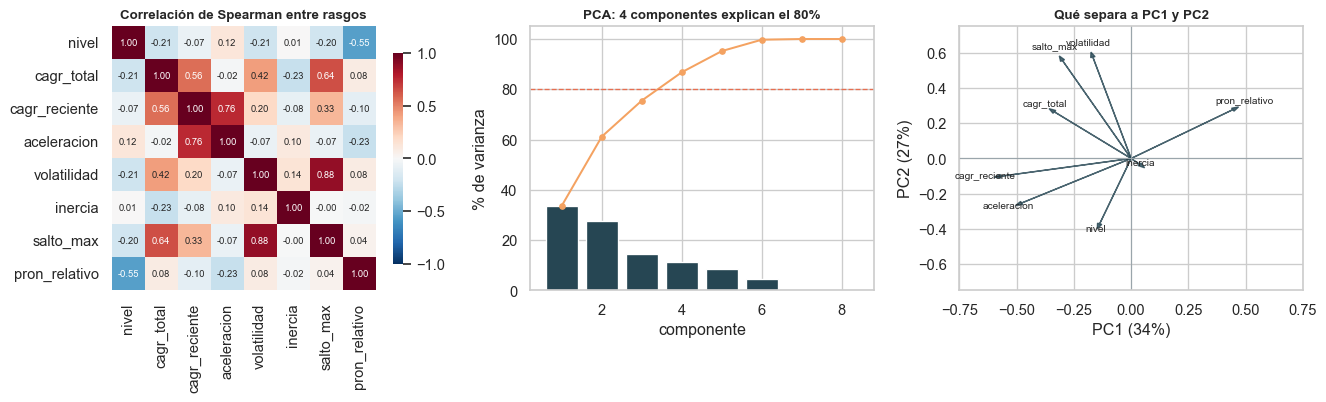

pares mas correlacionados:
  volatilidad      salto_max        +0.88
  cagr_reciente    aceleracion      +0.76
  cagr_total       salto_max        +0.64
  cagr_total       cagr_reciente    +0.56


In [4]:
corr = datos[RASGOS].corr(method="spearman")
guardar_tabla(corr.round(3), "t43_correlacion_rasgos.csv")

Z = StandardScaler().fit_transform(datos[RASGOS].values)
pca = PCA().fit(Z)
var = pca.explained_variance_ratio_

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": .8}, annot_kws={"size": 7}, ax=ax[0])
ax[0].set_title("Correlación de Spearman entre rasgos")

ax[1].bar(range(1, len(var) + 1), 100 * var, color=AZUL)
ax[1].plot(range(1, len(var) + 1), 100 * np.cumsum(var), "o-", color=NARANJA, ms=4)
ax[1].axhline(80, color=ROJO, ls="--", lw=1)
ax[1].set_xlabel("componente"); ax[1].set_ylabel("% de varianza")
ax[1].set_title("PCA: %d componentes explican el 80%%"
                % (np.searchsorted(np.cumsum(var), .8) + 1))

carga = pd.DataFrame(pca.components_[:2].T, index=RASGOS, columns=["PC1", "PC2"])
for r in RASGOS:
    ax[2].arrow(0, 0, carga.loc[r, "PC1"], carga.loc[r, "PC2"], color=AZUL,
                head_width=.02, alpha=.8)
    ax[2].text(carga.loc[r, "PC1"] * 1.12, carga.loc[r, "PC2"] * 1.12, r,
               fontsize=7.5, ha="center")
ax[2].axhline(0, color=GRIS, lw=.8); ax[2].axvline(0, color=GRIS, lw=.8)
ax[2].set_xlim(-.75, .75); ax[2].set_ylim(-.75, .75)
ax[2].set_xlabel("PC1 (%.0f%%)" % (100 * var[0])); ax[2].set_ylabel("PC2 (%.0f%%)" % (100 * var[1]))
ax[2].set_title("Qué separa a PC1 y PC2")

fig.tight_layout(); guardar_fig(fig, "clu_fig01_rasgos.png"); plt.show()

pares = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
         .sort_values(key=abs, ascending=False).head(4))
print("pares mas correlacionados:")
for (a, b), v in pares.items():
    print("  %-16s %-16s %+.2f" % (a, b, v))

## 2. ¿Hay realmente algo que agrupar?

Un algoritmo de clustering siempre devuelve clusters, incluso sobre ruido
uniforme. Antes de elegir k conviene preguntar si los datos tienen **tendencia
al agrupamiento**. El estadístico de Hopkins compara la distancia de puntos
reales a su vecino más cercano contra la de puntos artificiales sembrados al
azar en el mismo espacio:

- **≈ 0.5** → los datos están repartidos como ruido uniforme: no hay nada que agrupar.
- **> 0.75** → hay estructura y vale la pena seguir.

Hopkins de los datos        : 0.995
Hopkins de los datos barajados: 0.978  <- referencia con los mismos marginales
(0.5 seria ruido uniforme; con colas largas el estadistico se satura, por eso
 la comparacion contra la version barajada dice mas que el numero suelto)



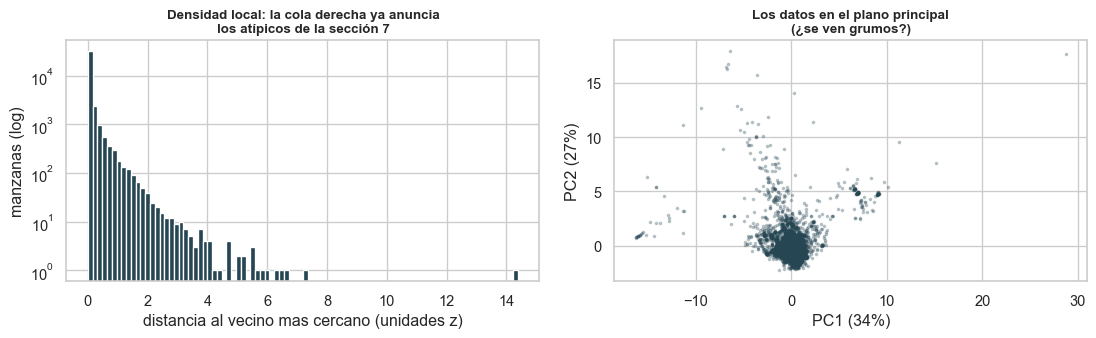

In [5]:
def hopkins(X, n=1500, semilla=SEMILLA):
    "Compara distancias de puntos reales y de puntos artificiales a sus vecinos."
    r = np.random.default_rng(semilla)
    n = min(n, len(X) - 1)
    vecino = NearestNeighbors(n_neighbors=2).fit(X)
    reales = X[r.choice(len(X), n, replace=False)]
    u = r.uniform(X.min(0), X.max(0), size=(n, X.shape[1]))
    d_real = vecino.kneighbors(reales, n_neighbors=2)[0][:, 1].sum()   # el 1o es el punto mismo
    d_art = vecino.kneighbors(u, n_neighbors=1)[0][:, 0].sum()
    return d_art / (d_art + d_real)

h = np.mean([hopkins(Z, semilla=SEMILLA + i) for i in range(5)])

# referencia honesta: las mismas ocho distribuciones, pero barajadas columna a columna.
# Conserva los marginales y destruye la estructura conjunta, asi que todo lo que
# quede por encima de este valor es estructura de verdad y no cola larga.
r = np.random.default_rng(SEMILLA)
Z_baraja = np.column_stack([r.permutation(col) for col in Z.T])
h_nulo = np.mean([hopkins(Z_baraja, semilla=SEMILLA + i) for i in range(5)])

print("Hopkins de los datos        : %.3f" % h)
print("Hopkins de los datos barajados: %.3f  <- referencia con los mismos marginales" % h_nulo)
print("(0.5 seria ruido uniforme; con colas largas el estadistico se satura, por eso")
print(" la comparacion contra la version barajada dice mas que el numero suelto)")
print()
d_vecino = NearestNeighbors(n_neighbors=2).fit(Z).kneighbors(Z)[0][:, 1]
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.6))
ax[0].hist(d_vecino, bins=90, color=AZUL)
ax[0].set_yscale("log"); ax[0].set_xlabel("distancia al vecino mas cercano (unidades z)")
ax[0].set_ylabel("manzanas (log)")
ax[0].set_title("Densidad local: la cola derecha ya anuncia\nlos atípicos de la sección 7")

sub = rng.choice(len(Z), min(8000, len(Z)), replace=False)
P = pca.transform(Z)[sub]
ax[1].scatter(P[:, 0], P[:, 1], s=3, alpha=.25, color=AZUL)
ax[1].set_xlabel("PC1 (%.0f%%)" % (100 * var[0])); ax[1].set_ylabel("PC2 (%.0f%%)" % (100 * var[1]))
ax[1].set_title("Los datos en el plano principal\n(¿se ven grumos?)")
fig.tight_layout(); guardar_fig(fig, "clu_fig02_hopkins.png"); plt.show()

## 3. Cuántos grupos: cinco criterios, y solo uno que importa de verdad

Los cuatro índices habituales miden **geometría**: qué tan compactos y separados
quedan los grupos. Ninguno sabe si la partición es *reproducible*, y esa es la
pregunta que decide si un k es real.

| Criterio | Qué mide | Se busca |
|---|---|---|
| Inercia (codo) | dispersión interna | el quiebre de la curva |
| Silueta | separación vs cohesión | máximo |
| Calinski-Harabasz | varianza entre / dentro | máximo |
| Davies-Bouldin | similitud entre grupos vecinos | mínimo |
| **Estabilidad (ARI)** | **¿sale la misma partición con otra muestra?** | **máximo** |

La estabilidad se mide remuestreando: se toman dos submuestras del 80 %, se
agrupa cada una por separado y se compara la etiqueta asignada a las manzanas
que están en ambas, con el índice de Rand ajustado. Un k que solo existe en una
muestra concreta se cae aquí y en ningún otro lado.

In [6]:
sub_sil = rng.choice(len(Z), min(N_SUBMUESTRA, len(Z)), replace=False)

filas = []
for k in K_RANGO:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Z)
    e = km.labels_
    filas.append({"k": k, "inercia": km.inertia_,
                  "silueta": silhouette_score(Z[sub_sil], e[sub_sil]),
                  "calinski_harabasz": calinski_harabasz_score(Z, e),
                  "davies_bouldin": davies_bouldin_score(Z, e)})
indices = pd.DataFrame(filas).set_index("k")

def estabilidad(k, reps=N_BOOTSTRAP_ARI, frac=.8):
    "ARI medio entre dos particiones independientes del 80% de los datos."
    aris = []
    for i in range(reps):
        r = np.random.default_rng(SEMILLA + 100 * k + i)
        a = r.choice(len(Z), int(frac * len(Z)), replace=False)
        b = r.choice(len(Z), int(frac * len(Z)), replace=False)
        ea = MiniBatchKMeans(k, n_init=5, random_state=SEMILLA, batch_size=2048).fit(Z[a])
        eb = MiniBatchKMeans(k, n_init=5, random_state=SEMILLA + 1, batch_size=2048).fit(Z[b])
        comun = np.intersect1d(a, b)
        aris.append(adjusted_rand_score(ea.predict(Z[comun]), eb.predict(Z[comun])))
    return np.mean(aris), np.std(aris)

est = [estabilidad(k) for k in K_RANGO]
indices["estabilidad_ari"] = [e[0] for e in est]
indices["estabilidad_sd"] = [e[1] for e in est]
guardar_tabla(indices.round(4), "t44_indices_por_k.csv")

k_sil = int(indices["silueta"].idxmax())
k_ch = int(indices["calinski_harabasz"].idxmax())
k_db = int(indices["davies_bouldin"].idxmin())
k_est = int(indices["estabilidad_ari"].idxmax())
print("silueta -> k=%d | Calinski-Harabasz -> k=%d | Davies-Bouldin -> k=%d | estabilidad -> k=%d"
      % (k_sil, k_ch, k_db, k_est))
indices.round(3)

silueta -> k=3 | Calinski-Harabasz -> k=6 | Davies-Bouldin -> k=4 | estabilidad -> k=10


,inercia,silueta,calinski_harabasz,davies_bouldin,estabilidad_ari,estabilidad_sd
k,,,,,,
2,244113.121,0.708,8500.321,1.238,0.312,0.282
3,196823.858,0.730,9768.734,0.985,0.278,0.169
4,171116.675,0.717,9365.467,0.771,0.389,0.224
5,146041.151,0.260,9836.931,1.084,0.424,0.207
6,125180.171,0.280,10428.470,1.084,0.466,0.186
7,116623.155,0.268,9785.598,1.161,0.464,0.099
8,107908.189,0.254,9496.702,1.138,0.431,0.119
9,101423.607,0.256,9139.816,1.114,0.434,0.139
10,95493.278,0.228,8886.873,1.146,0.498,0.086


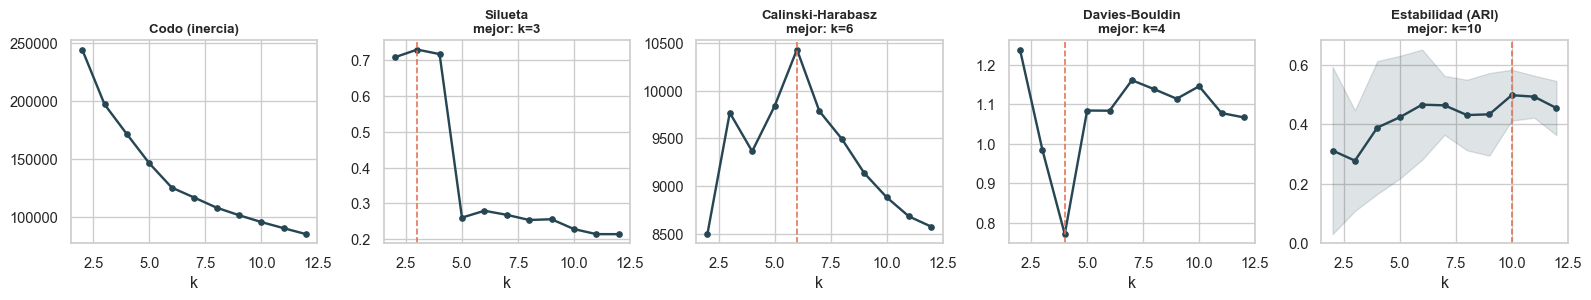

In [7]:
fig, ax = plt.subplots(1, 5, figsize=(16.5, 3.2))
series = [("inercia", "Codo (inercia)", None), ("silueta", "Silueta", "max"),
          ("calinski_harabasz", "Calinski-Harabasz", "max"),
          ("davies_bouldin", "Davies-Bouldin", "min"),
          ("estabilidad_ari", "Estabilidad (ARI)", "max")]
for a, (col, titulo, criterio) in zip(ax, series):
    a.plot(indices.index, indices[col], "o-", color=AZUL, lw=1.8, ms=4)
    if col == "estabilidad_ari":
        a.fill_between(indices.index, indices[col] - indices["estabilidad_sd"],
                       indices[col] + indices["estabilidad_sd"], color=AZUL, alpha=.15)
    if criterio:
        mejor = indices[col].idxmax() if criterio == "max" else indices[col].idxmin()
        a.axvline(mejor, color=ROJO, ls="--", lw=1.2)
        a.set_title("%s\nmejor: k=%d" % (titulo, mejor))
    else:
        a.set_title(titulo)
    a.set_xlabel("k")
fig.tight_layout(); guardar_fig(fig, "clu_fig03_eleccion_k.png"); plt.show()

Cuando los criterios no coinciden —y casi nunca coinciden— manda la
**estabilidad**, con una condición: que el k elegido no sea absurdo en los demás
índices. La celda siguiente aplica esa regla y deja el valor en `K`.

In [8]:
if K_ELEGIDO is not None:
    K = K_ELEGIDO
    motivo = "fijado a mano en los parametros"
else:
    # se parte de la estabilidad y se exige que la silueta no sea de las peores
    orden = indices.sort_values("estabilidad_ari", ascending=False)
    aceptable = orden[orden["silueta"] >= indices["silueta"].quantile(.4)]
    K = int((aceptable if len(aceptable) else orden).index[0])
    motivo = "maxima estabilidad entre los k con silueta aceptable"

print("k elegido: %d  (%s)" % (K, motivo))
print("  estabilidad ARI %.3f | silueta %.3f | Davies-Bouldin %.3f"
      % (indices.loc[K, "estabilidad_ari"], indices.loc[K, "silueta"],
         indices.loc[K, "davies_bouldin"]))

k elegido: 6  (maxima estabilidad entre los k con silueta aceptable)
  estabilidad ARI 0.466 | silueta 0.280 | Davies-Bouldin 1.084


## 4. Seis algoritmos sobre los mismos datos

Cada uno define "grupo" de una manera distinta, y por eso vale la pena correrlos
todos en vez de casarse con K-Means:

| Algoritmo | Qué supone que es un cluster | Cuándo gana |
|---|---|---|
| **K-Means** | una bola alrededor de un centro | grupos de tamaño parecido |
| **Mezcla gaussiana** | una elipse con su propia forma | grupos alargados o solapados |
| **Jerárquico (Ward)** | lo que queda al fusionar lo más parecido | cuando interesa el árbol, no solo el corte |
| **BIRCH** | resúmenes comprimidos de la nube | muchos datos, poca memoria |
| **DBSCAN** | una región densa rodeada de vacío | formas raras **y detectar ruido** |
| **Ward con contigüidad** | lo anterior, pero obligado a ser vecino | cuando el resultado va a un mapa |

Antes de comparar hay que ajustar cada uno. Las tres celdas siguientes son las
rejillas de hiperparámetros.

### 4.1 Mezcla gaussiana: tipo de covarianza y número de componentes por BIC

mejor por BIC: covarianza=full, k=12
(el BIC casi siempre pide mas componentes que la silueta: penaliza poco
 la complejidad cuando hay decenas de miles de observaciones)


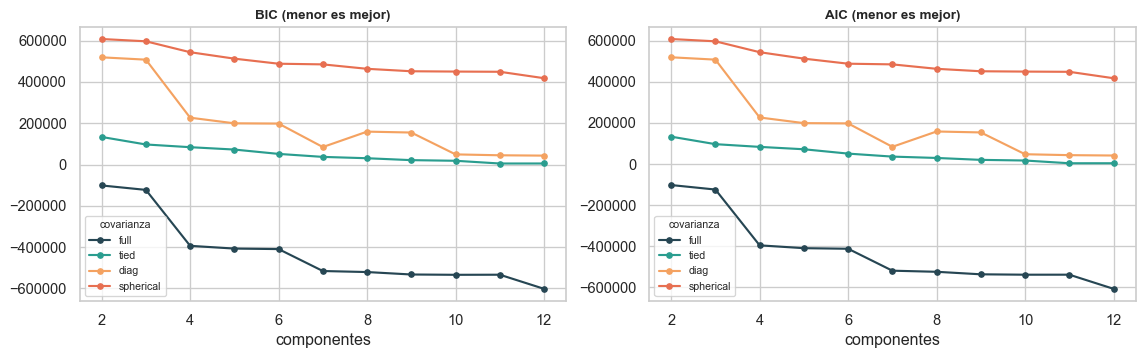

In [9]:
filas = []
for cov in COVARIANZAS_GMM:
    for k in K_RANGO:
        g = GaussianMixture(k, covariance_type=cov, random_state=SEMILLA,
                            n_init=1, max_iter=200).fit(Z)
        filas.append({"covarianza": cov, "k": k, "bic": g.bic(Z), "aic": g.aic(Z),
                      "converge": g.converged_})
rejilla_gmm = pd.DataFrame(filas)
guardar_tabla(rejilla_gmm.round(1), "t45_rejilla_gmm.csv", index=False)

mejor_gmm = rejilla_gmm.loc[rejilla_gmm["bic"].idxmin()]
print("mejor por BIC: covarianza=%s, k=%d" % (mejor_gmm["covarianza"], mejor_gmm["k"]))
print("(el BIC casi siempre pide mas componentes que la silueta: penaliza poco")
print(" la complejidad cuando hay decenas de miles de observaciones)")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for cov, col in zip(COVARIANZAS_GMM, [AZUL, VERDE, NARANJA, ROJO]):
    d = rejilla_gmm[rejilla_gmm["covarianza"] == cov]
    ax[0].plot(d["k"], d["bic"], "o-", color=col, lw=1.6, ms=4, label=cov)
    ax[1].plot(d["k"], d["aic"], "o-", color=col, lw=1.6, ms=4, label=cov)
ax[0].set_title("BIC (menor es mejor)"); ax[1].set_title("AIC (menor es mejor)")
for a in ax:
    a.set_xlabel("componentes"); a.legend(fontsize=8, title="covarianza", title_fontsize=8)
fig.tight_layout(); guardar_fig(fig, "clu_fig04_gmm_bic.png"); plt.show()

COV_GMM = mejor_gmm["covarianza"]

### 4.2 DBSCAN: la rejilla de `eps` y `min_samples`

DBSCAN no recibe el número de grupos: lo deduce de la densidad. `eps` es el
radio del vecindario y `min_samples` cuántos puntos hacen falta dentro para
considerarlo denso. La rejilla muestra el compromiso: con `eps` chico casi todo
es ruido; con `eps` grande todo colapsa en un solo grupo. Interesa la franja
intermedia, y de paso el **ruido es el primer insumo para las atípicas** de la
sección 7.

In [10]:
filas = []
for eps in DBSCAN_EPS:
    for ms in DBSCAN_MIN:
        e = DBSCAN(eps=eps, min_samples=ms, n_jobs=-1).fit_predict(Z)
        n_cl = len(set(e)) - (1 if -1 in e else 0)
        filas.append({"eps": eps, "min_samples": ms, "clusters": n_cl,
                      "pct_ruido": round(100 * np.mean(e == -1), 1),
                      "pct_mayor": round(100 * pd.Series(e[e != -1]).value_counts(normalize=True).max(), 1)
                      if n_cl else np.nan})
rejilla_db = pd.DataFrame(filas)
guardar_tabla(rejilla_db, "t46_rejilla_dbscan.csv", index=False)

# el uso que se le dara a DBSCAN es detectar rarezas, asi que se elige la
# configuracion cuyo nivel de ruido quede mas cerca del 5%: suficiente para
# marcar lo raro sin declarar rara a una de cada cuatro manzanas
RUIDO_OBJETIVO = 5.0
util = rejilla_db.query("clusters >= 2")
elegida = (util.assign(d=(util["pct_ruido"] - RUIDO_OBJETIVO).abs())
           .sort_values("d").iloc[0] if len(util) else rejilla_db.iloc[0])
EPS, MIN_S = float(elegida["eps"]), int(elegida["min_samples"])
print("configuracion elegida: eps=%.2f, min_samples=%d -> %d grupos, %.1f%% de ruido"
      % (EPS, MIN_S, elegida["clusters"], elegida["pct_ruido"]))
print()
print(rejilla_db.pivot(index="eps", columns="min_samples", values="pct_ruido")
      .rename_axis(columns="min_samples").to_string())
rejilla_db

configuracion elegida: eps=1.00, min_samples=25 -> 13 grupos, 5.9% de ruido

min_samples    25    50
eps                    
0.3          26.1  35.1
0.5          14.4  18.6
0.7           9.3  11.4
1.0           5.9   7.2


,eps,min_samples,clusters,pct_ruido,pct_mayor
0,0.3,25,117,26.1,55.5
1,0.3,50,62,35.1,59.9
2,0.5,25,47,14.4,65.6
3,0.5,50,27,18.6,68.2
4,0.7,25,29,9.3,64.5
5,0.7,50,18,11.4,65.6
6,1.0,25,13,5.9,65.8
7,1.0,50,11,7.2,65.9


### 4.3 Jerárquico: qué tipo de enlace

In [11]:
sub_h = rng.choice(len(Z), min(N_SUBMUESTRA, len(Z)), replace=False)
Zh = Z[sub_h]

filas = []
for enlace in ENLACES:
    e = AgglomerativeClustering(n_clusters=K, linkage=enlace).fit_predict(Zh)
    filas.append({"enlace": enlace, "silueta": round(silhouette_score(Zh, e), 4),
                  "davies_bouldin": round(davies_bouldin_score(Zh, e), 3),
                  "grupo_mayor_pct": round(100 * pd.Series(e).value_counts(normalize=True).max(), 1)})
rejilla_enl = pd.DataFrame(filas).sort_values("silueta", ascending=False)
guardar_tabla(rejilla_enl, "t47_rejilla_enlace.csv", index=False)

# una particion donde un grupo se lleva casi todo tiene silueta altisima y no sirve
# para nada: se exige que el grupo mayor no pase del 90%
sanos = rejilla_enl[rejilla_enl["grupo_mayor_pct"] < 90]
ENLACE = (sanos if len(sanos) else rejilla_enl).iloc[0]["enlace"]
descartados = rejilla_enl[rejilla_enl["grupo_mayor_pct"] >= 90]["enlace"].tolist()
print("enlace elegido: %s" % ENLACE)
if descartados:
    print("descartados por degenerados (un grupo con >90%% de las manzanas): %s"
          % ", ".join(descartados))
    print("  y eran justamente los de mejor silueta: el indice premia una particion inutil")
rejilla_enl

enlace elegido: ward
descartados por degenerados (un grupo con >90% de las manzanas): average, complete
  y eran justamente los de mejor silueta: el indice premia una particion inutil


,enlace,silueta,davies_bouldin,grupo_mayor_pct
2,average,0.7789,0.584,99.1
1,complete,0.6485,0.849,97.4
0,ward,0.2166,1.105,48.0


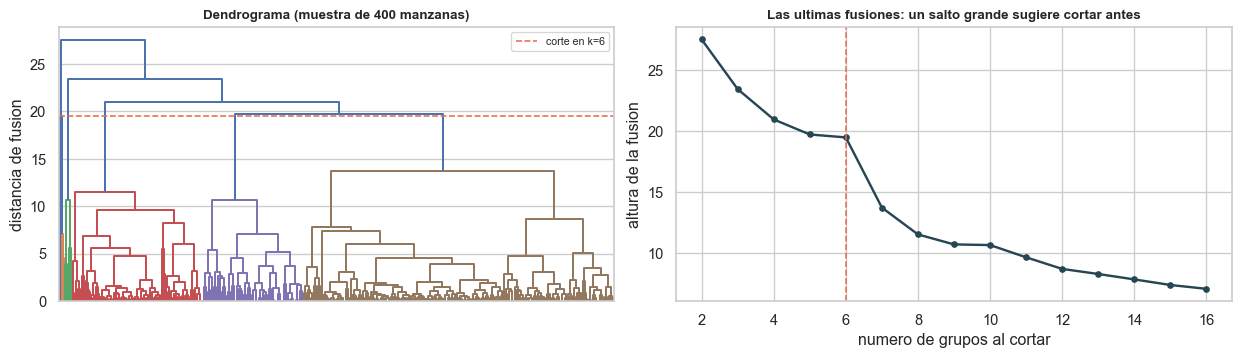

In [12]:
# el dendrograma sobre una submuestra pequeña: la altura de cada fusion dice
# cuanto cuesta unir dos ramas, y los saltos grandes sugieren donde cortar
peq = rng.choice(len(Z), 400, replace=False)
enlazado = scipy_linkage(Z[peq], method="ward")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
dendrogram(enlazado, no_labels=True, color_threshold=enlazado[-(K - 1), 2], ax=ax[0])
ax[0].axhline(enlazado[-(K - 1), 2], color=ROJO, ls="--", lw=1.2,
              label="corte en k=%d" % K)
ax[0].set_title("Dendrograma (muestra de 400 manzanas)")
ax[0].set_ylabel("distancia de fusion"); ax[0].legend(fontsize=8)

alturas = enlazado[-15:, 2][::-1]
ax[1].plot(range(2, 17), alturas, "o-", color=AZUL, lw=1.8, ms=4)
ax[1].axvline(K, color=ROJO, ls="--", lw=1.2)
ax[1].set_xlabel("numero de grupos al cortar"); ax[1].set_ylabel("altura de la fusion")
ax[1].set_title("Las ultimas fusiones: un salto grande sugiere cortar antes")
fig.tight_layout(); guardar_fig(fig, "clu_fig04b_dendrograma.png"); plt.show()

### 4.4 Ajuste final y comparación

Con los hiperparámetros fijados, los cinco algoritmos libres se ajustan sobre
los mismos datos y se comparan con los mismos índices. Se añade la **pureza
espacial** —qué fracción de los 8 vecinos geográficos de una manzana comparte su
etiqueta— que no se usó para agrupar y por lo tanto es un resultado, no un
supuesto: mide cuánto se parecen estos grupos a zonas de verdad.

In [13]:
XY = np.c_[datos["lon"].values * np.cos(np.radians(4.65)), datos["lat"].values]
IDX_ESP = NearestNeighbors(n_neighbors=K_VECINOS_ESPACIAL + 1).fit(XY).kneighbors(XY)[1][:, 1:]

def pureza_espacial(e):
    "Fraccion de vecinos geograficos que comparten etiqueta (0 a 1)."
    return float(np.mean(e[IDX_ESP] == e[:, None]))

km = KMeans(K, n_init=10, random_state=SEMILLA).fit(Z)
gmm = GaussianMixture(K, covariance_type=COV_GMM, random_state=SEMILLA, n_init=3).fit(Z)
ward_sub = AgglomerativeClustering(n_clusters=K, linkage=ENLACE).fit(Zh)
centros_w = np.array([Zh[ward_sub.labels_ == c].mean(0) for c in range(K)])
birch = Birch(n_clusters=K).fit(Z)
db = DBSCAN(eps=EPS, min_samples=MIN_S, n_jobs=-1).fit(Z)

etiquetas = {
    "K-Means": km.labels_,
    "Mezcla gaussiana": gmm.predict(Z),
    "Jerarquico (%s)" % ENLACE: np.argmin(((Z[:, None, :] - centros_w[None]) ** 2).sum(-1), axis=1),
    "BIRCH": birch.predict(Z),
    "DBSCAN": db.labels_,
}

filas = []
for nombre, e in etiquetas.items():
    valido = e != -1
    n_cl = len(set(e[valido]))
    sil = (silhouette_score(Z[sub_sil][e[sub_sil] != -1], e[sub_sil][e[sub_sil] != -1])
           if len(set(e[sub_sil][e[sub_sil] != -1])) > 1 else np.nan)
    filas.append({"algoritmo": nombre, "grupos": n_cl,
                  "pct_sin_asignar": round(100 * np.mean(~valido), 1),
                  "silueta": round(sil, 4) if sil == sil else np.nan,
                  "calinski_harabasz": round(calinski_harabasz_score(Z[valido], e[valido]), 0)
                  if n_cl > 1 else np.nan,
                  "davies_bouldin": round(davies_bouldin_score(Z[valido], e[valido]), 3)
                  if n_cl > 1 else np.nan,
                  "grupo_mayor_pct": round(100 * pd.Series(e[valido]).value_counts(normalize=True).max(), 1),
                  "pureza_espacial": round(pureza_espacial(e), 3)})
comparacion = pd.DataFrame(filas)
guardar_tabla(comparacion, "t48_comparacion_algoritmos.csv", index=False)
print("pureza espacial si las etiquetas se repartieran al azar: %.3f\n" % (1 / K))
comparacion

pureza espacial si las etiquetas se repartieran al azar: 0.167



,algoritmo,grupos,pct_sin_asignar,silueta,calinski_harabasz,davies_bouldin,grupo_mayor_pct,pureza_espacial
0,K-Means,6,0.0,0.2796,10428.0,1.084,58.7,0.864
1,Mezcla gaussiana,6,0.0,0.2077,5519.0,1.891,58.3,0.763
2,Jerarquico (ward),6,0.0,0.2418,9971.0,1.080,46.3,0.821
3,BIRCH,6,0.0,0.5075,6391.0,0.963,92.1,0.927
4,DBSCAN,13,5.9,0.2015,3147.0,1.030,65.8,0.773


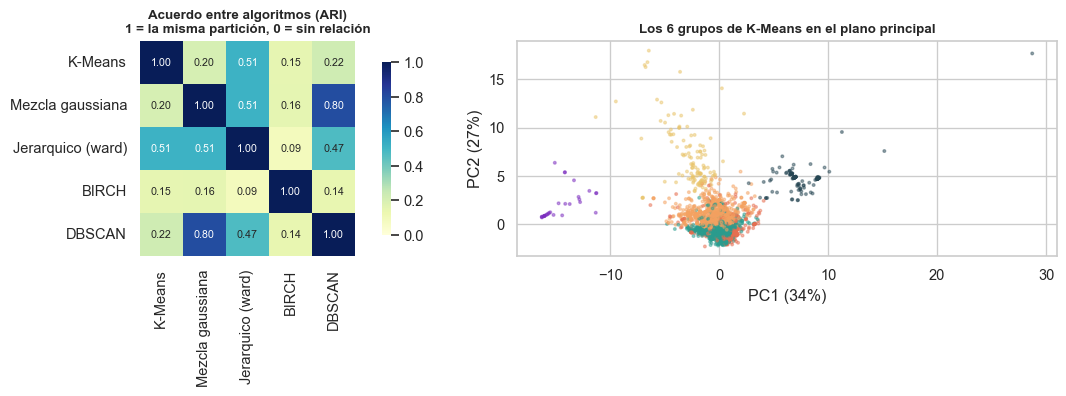

In [14]:
# ¿los algoritmos encuentran lo mismo? ARI entre cada par
nombres = list(etiquetas)
A = pd.DataFrame(index=nombres, columns=nombres, dtype=float)
for a in nombres:
    for b in nombres:
        A.loc[a, b] = adjusted_rand_score(etiquetas[a], etiquetas[b])
guardar_tabla(A.round(3), "t49_acuerdo_entre_algoritmos.csv")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
sns.heatmap(A.astype(float), annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1,
            square=True, cbar_kws={"shrink": .8}, annot_kws={"size": 8}, ax=ax[0])
ax[0].set_title("Acuerdo entre algoritmos (ARI)\n1 = la misma partición, 0 = sin relación")

P = pca.transform(Z)
col_km = [PALETA[c % len(PALETA)] for c in km.labels_[sub]]
ax[1].scatter(P[sub, 0], P[sub, 1], s=4, alpha=.45, c=col_km)
ax[1].set_xlabel("PC1 (%.0f%%)" % (100 * var[0])); ax[1].set_ylabel("PC2 (%.0f%%)" % (100 * var[1]))
ax[1].set_title("Los %d grupos de K-Means en el plano principal" % K)
fig.tight_layout(); guardar_fig(fig, "clu_fig05_acuerdo.png"); plt.show()

## 5. La versión contigua: cuando el resultado va a un mapa

Los grupos anteriores son **tipologías**: una manzana de Suba puede pertenecer
al mismo grupo que una de Kennedy si se comportan igual. Es lo correcto
analíticamente, y es incómodo si lo que se quiere es dibujar zonas de gestión.

La variante contigua resuelve eso imponiendo una **matriz de conectividad**: dos
manzanas solo pueden fusionarse si son vecinas geográficas. El algoritmo sigue
optimizando el parecido de comportamiento, pero dentro de esa restricción. La
pregunta interesante es **cuánto cuesta**: cuánta homogeneidad de comportamiento
se sacrifica a cambio de cuánta compacidad en el mapa.

In [15]:
conect = kneighbors_graph(XY, K_VECINOS_ESPACIAL, include_self=False)
ward_esp = AgglomerativeClustering(n_clusters=K, linkage="ward", connectivity=conect).fit(Z)
etiquetas["Ward contiguo"] = ward_esp.labels_

costo = pd.DataFrame([
    {"version": "libre (K-Means)", "silueta": comparacion.set_index("algoritmo").loc["K-Means", "silueta"],
     "pureza_espacial": comparacion.set_index("algoritmo").loc["K-Means", "pureza_espacial"],
     "grupo_mayor_pct": comparacion.set_index("algoritmo").loc["K-Means", "grupo_mayor_pct"]},
    {"version": "contigua (Ward + vecindad)",
     "silueta": round(silhouette_score(Z[sub_sil], ward_esp.labels_[sub_sil]), 4),
     "pureza_espacial": round(pureza_espacial(ward_esp.labels_), 3),
     "grupo_mayor_pct": round(100 * pd.Series(ward_esp.labels_).value_counts(normalize=True).max(), 1)},
])
guardar_tabla(costo, "t50_libre_vs_contigua.csv", index=False)
print("acuerdo entre la version libre y la contigua: ARI = %.3f"
      % adjusted_rand_score(km.labels_, ward_esp.labels_))
print()
costo

acuerdo entre la version libre y la contigua: ARI = 0.258



,version,silueta,pureza_espacial,grupo_mayor_pct
0,libre (K-Means),0.2796,0.864,58.7
1,contigua (Ward + vecindad),0.1113,0.968,55.6


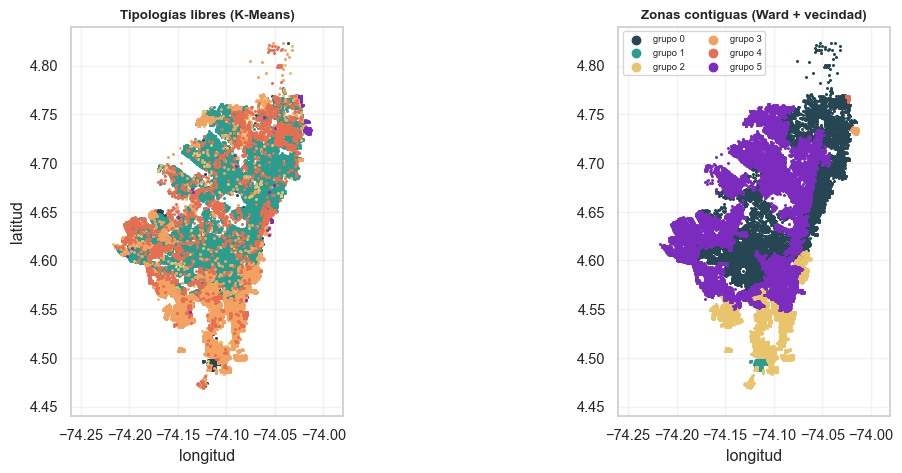

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, (nombre, e) in zip(ax, [("Tipologías libres (K-Means)", km.labels_),
                               ("Zonas contiguas (Ward + vecindad)", ward_esp.labels_)]):
    for c in range(K):
        m = (e == c) & datos["lon"].between(*C.URB_LON) & datos["lat"].between(*C.URB_LAT)
        a.scatter(datos.loc[m, "lon"], datos.loc[m, "lat"], s=1.6,
                  color=PALETA[c % len(PALETA)], label="grupo %d" % c)
    formato_mapa(a, nombre)
ax[0].set_ylabel("latitud")
ax[1].legend(fontsize=7, markerscale=5, loc="upper left", ncol=2)
fig.tight_layout(); guardar_fig(fig, "clu_fig06_libre_vs_contigua.png"); plt.show()

## 6. Quiénes son estos grupos

Se trabaja de aquí en adelante con la partición de **K-Means**, por ser la más
estable y la que los demás algoritmos más reproducen. El perfil se lee en
unidades estandarizadas: un +1 significa "una desviación típica por encima del
promedio de la ciudad en ese rasgo".

In [17]:
datos["cluster"] = km.labels_
perfil_z = (pd.DataFrame(Z, columns=RASGOS).groupby(km.labels_).mean())

precio_cluster = datos.groupby("cluster")["cop_m2_2026"].median()
cuantil = precio_cluster.rank(pct=True) * 0   # se rellena abajo con el percentil real
for c_ in precio_cluster.index:
    cuantil[c_] = (datos["cop_m2_2026"] < precio_cluster[c_]).mean()

def bautizar(fila):
    "Nombre corto: el nivel se mide contra la distribucion real de precios de la ciudad."
    q = cuantil[fila.name]
    nivel = "caro" if q > .66 else ("barato" if q < .33 else "medio")
    if fila["cagr_reciente"] > .5:
        din = "acelerando"
    elif fila["cagr_reciente"] < -.5:
        din = "estancado"
    else:
        din = "al ritmo de la ciudad"
    extra = " e inestable" if fila["volatilidad"] > .8 else (" y quieto" if fila["inercia"] > .8 else "")
    return "%s, %s%s" % (nivel, din, extra)

nombres_cl = {c: bautizar(perfil_z.loc[c]) for c in perfil_z.index}

perfil = pd.DataFrame({
    "nombre": pd.Series(nombres_cl),
    "manzanas": datos.groupby("cluster").size(),
    "pct": (100 * datos.groupby("cluster").size() / len(datos)).round(1),
    "precio_2026": datos.groupby("cluster")["cop_m2_2026"].median().round(0),
    "cagr_total_pct": datos.groupby("cluster")["cagr_total"].median().map(pct).round(1),
    "cagr_reciente_pct": datos.groupby("cluster")["cagr_reciente"].median().map(pct).round(1),
    "volatilidad": datos.groupby("cluster")["volatilidad"].median().round(4),
    "inercia": datos.groupby("cluster")["inercia"].median().round(2),
    "pron_relativo": datos.groupby("cluster")["pron_relativo"].median().round(2),
})
guardar_tabla(perfil, "t51_perfil_clusters.csv")
perfil

,nombre,manzanas,pct,precio_2026,cagr_total_pct,cagr_reciente_pct,volatilidad,inercia,pron_relativo
0,"barato, estancado e inestable",573,1.5,295200.0,1.0,-25.0,0.1834,0.00,4.99
1,"caro, al ritmo de la ciudad",21985,58.7,3331000.0,8.2,7.5,0.0266,0.00,-0.07
2,"barato, al ritmo de la ciudad e inestable",633,1.7,1900000.0,23.7,8.6,0.2761,0.00,0.11
3,"barato, al ritmo de la ciudad",10799,28.8,1420000.0,11.0,10.1,0.0363,0.00,0.17
4,"medio, al ritmo de la ciudad y quieto",3307,8.8,2670000.0,6.2,6.8,0.0347,0.25,-0.03
5,"barato, acelerando e inestable",145,0.4,1200000.0,9.1,102.0,0.4281,0.00,-8.90


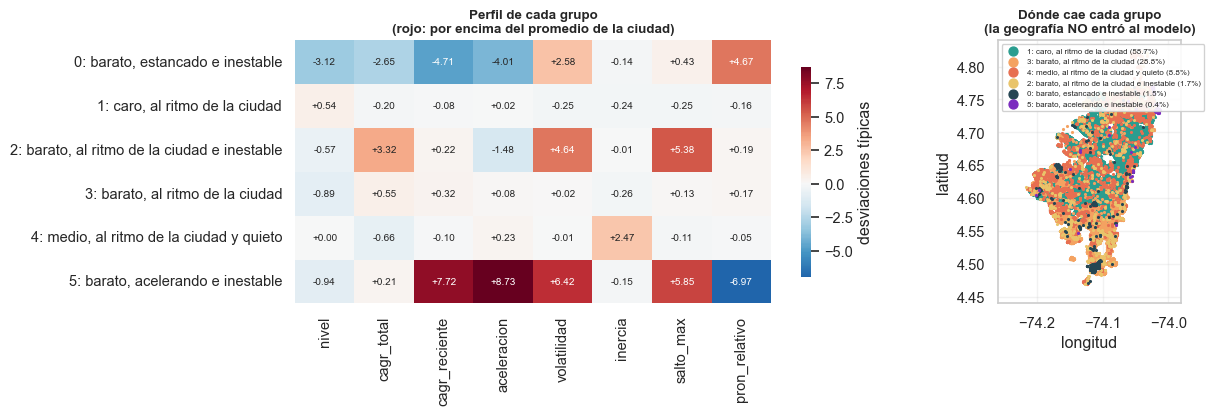

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4),
                       gridspec_kw={"width_ratios": [1.25, 1]})
etq = ["%d: %s" % (c, nombres_cl[c]) for c in perfil_z.index]
sns.heatmap(perfil_z.set_axis(etq), annot=True, fmt="+.2f", cmap="RdBu_r", center=0,
            cbar_kws={"shrink": .8, "label": "desviaciones típicas"},
            annot_kws={"size": 7.5}, ax=ax[0])
ax[0].set_title("Perfil de cada grupo\n(rojo: por encima del promedio de la ciudad)")
ax[0].set_xlabel("")

orden_dibujo = perfil.sort_values("manzanas", ascending=False).index   # los chicos, encima
for c in orden_dibujo:
    m = (datos["cluster"] == c) & datos["lon"].between(*C.URB_LON) & datos["lat"].between(*C.URB_LAT)
    ax[1].scatter(datos.loc[m, "lon"], datos.loc[m, "lat"], s=1.8,
                  color=PALETA[c % len(PALETA)],
                  label="%d: %s (%.1f%%)" % (c, nombres_cl[c], perfil.loc[c, "pct"]))
formato_mapa(ax[1], "Dónde cae cada grupo\n(la geografía NO entró al modelo)")
ax[1].set_ylabel("latitud")
ax[1].legend(fontsize=6, markerscale=5, loc="upper left", framealpha=.9)
fig.tight_layout(); guardar_fig(fig, "clu_fig07_perfil.png"); plt.show()

### Validación externa: ¿los grupos coinciden con la ciudad real?

Ninguna de estas variables participó en el agrupamiento. Si los grupos se
diferencian también aquí, es que capturaron algo genuino del territorio y no un
corte arbitrario del espacio de rasgos.

> **Cómo leer la pureza espacial.** Saldrá muy alta, y conviene saber por qué
> antes de celebrarlo: Catastro asigna `V_REF` **por zonas homogéneas**, de modo
> que manzanas vecinas suelen compartir literalmente el mismo valor y la misma
> historia. Parte de esa pureza mide el procedimiento administrativo, no el
> mercado. Lo que sí es informativo es la **comparación entre algoritmos**: los
> que encuentran grupos más compactos en el espacio de rasgos no son
> necesariamente los que dibujan zonas más limpias.

In [19]:
uso = pd.read_csv(F_USO, dtype={"MANCODIGO": str})
uso["uso"] = uso["GRUPOUSOECON"].map(
    lambda v: "".join(ch for ch in unicodedata.normalize("NFD", str(v))
                      if unicodedata.category(ch) != "Mn").upper().strip())
uso = uso.rename(columns={"MANCODIGO": "manzana"})[["manzana", "uso"]].drop_duplicates("manzana")
mz = pd.read_csv(C.F_DATASET, dtype={"manzana": str, "sector": str})
ext = datos.merge(uso, on="manzana", how="left").merge(
    mz[["manzana", "dist_eje_financiero_km", "dist_centro_historico_km", "vecinos_1km"]],
    on="manzana", how="left")

externas = ["dist_eje_financiero_km", "dist_centro_historico_km", "vecinos_1km", "ivs"]
validacion = ext.groupby("cluster")[externas].median().round(2)
validacion.insert(0, "nombre", pd.Series(nombres_cl))
# dispersion entre grupos frente a dispersion total: cuanto separa el cluster
razon = {v: round(ext.groupby("cluster")[v].mean().std() / ext[v].std(), 3) for v in externas}
guardar_tabla(validacion, "t52_validacion_externa.csv")
print("separacion entre grupos / dispersion total (0 = el cluster no dice nada de esa variable):")
for v, r in razon.items():
    print("  %-26s %.3f" % (v, r))
print()
print("pureza espacial de K-Means: %.3f  (al azar seria %.3f)"
      % (pureza_espacial(km.labels_), 1 / K))
validacion

separacion entre grupos / dispersion total (0 = el cluster no dice nada de esa variable):
  dist_eje_financiero_km     0.790
  dist_centro_historico_km   0.644
  vecinos_1km                0.627
  ivs                        0.315

pureza espacial de K-Means: 0.864  (al azar seria 0.167)


,nombre,dist_eje_financiero_km,dist_centro_historico_km,vecinos_1km,ivs
cluster,,,,,
0,"barato, estancado e inestable",21.93,11.97,503.0,36.39
1,"caro, al ritmo de la ciudad",9.75,10.27,368.0,55.58
2,"barato, al ritmo de la ciudad e inestable",14.66,10.18,361.0,37.41
3,"barato, al ritmo de la ciudad",17.18,9.57,509.0,37.99
4,"medio, al ritmo de la ciudad y quieto",13.46,11.22,321.0,72.66
5,"barato, acelerando e inestable",7.35,16.73,188.0,30.41


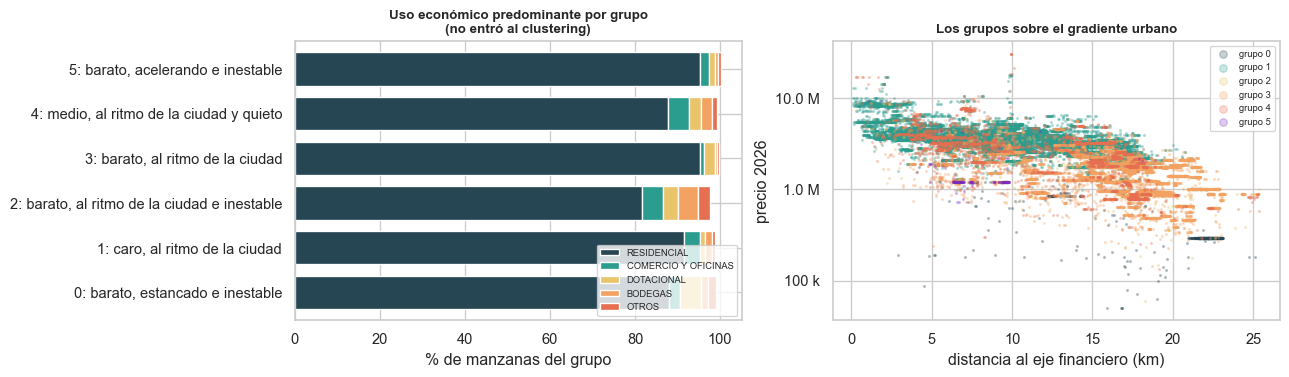

In [20]:
mezcla = (pd.crosstab(ext["cluster"], ext["uso"], normalize="index") * 100).round(1)
principales = mezcla.sum().sort_values(ascending=False).head(5).index
mezcla = mezcla[principales]
mezcla.index = etq
guardar_tabla(mezcla, "t52b_uso_por_cluster.csv")

fig, ax = plt.subplots(1, 2, figsize=(13.5, 4))
mezcla.plot(kind="barh", stacked=True, ax=ax[0],
            color=PALETA[:len(principales)], width=.75)
ax[0].set_xlabel("% de manzanas del grupo"); ax[0].set_ylabel("")
ax[0].set_title("Uso económico predominante por grupo\n(no entró al clustering)")
ax[0].legend(fontsize=7, loc="lower right")

for c in range(K):
    d = ext[ext["cluster"] == c]
    ax[1].scatter(d["dist_eje_financiero_km"], d["cop_m2_2026"], s=2, alpha=.25,
                  color=PALETA[c % len(PALETA)], label="grupo %d" % c)
ax[1].set_yscale("log"); ax[1].yaxis.set_major_formatter(mticker.FuncFormatter(pesos))
ax[1].set_xlabel("distancia al eje financiero (km)"); ax[1].set_ylabel("precio 2026")
ax[1].set_title("Los grupos sobre el gradiente urbano")
ax[1].legend(fontsize=7, markerscale=4)
fig.tight_layout(); guardar_fig(fig, "clu_fig08_validacion_externa.png"); plt.show()

## 7. Las zonas que destacan

Dos lecturas distintas de "destacar", y conviene no confundirlas.

### 7.1 Oportunidad: crecer más de lo que el precio haría esperar

El notebook de pronóstico dejó claro que el suelo barato se valoriza más rápido
en porcentaje. Entonces "las zonas que más crecen" es, casi por definición, "las
zonas más baratas" —una lista inútil—. La medida de oportunidad corrige eso:

> **oportunidad = crecimiento reciente observado − el crecimiento que le
> correspondería a una manzana de ese precio**

Lo segundo se estima con una regresión isotónica del crecimiento sobre el nivel
de precio, que no impone forma funcional. El residuo es lo que queda después de
descontar la reversión a la media: una manzana con oportunidad alta crece más
que *sus pares de precio*, no más que la ciudad.

In [21]:
# el precio de referencia es el del INICIO de la ventana, no el del final:
# usar el de 2026 contaminaria la medida, porque una manzana que salto en
# 2024-2026 llega a 2026 cara justamente por haber saltado
# ademas se recorta el objetivo a su rango central: sin eso, media docena de
# revaluos administrativos del 200% definen lo "esperado" para todo un tramo de precio
recortado = datos["cagr_reciente"].clip(*np.percentile(datos["cagr_reciente"], [1, 99]))
iso = IsotonicRegression(increasing=False, out_of_bounds="clip").fit(
    datos["nivel_inicio"], recortado)
datos["esperado"] = iso.predict(datos["nivel_inicio"])
datos["oportunidad"] = datos["cagr_reciente"] - datos["esperado"]

print("crecimiento bruto vs precio de %d : %+.3f  <- la reversion a la media"
      % (ANIO_RECIENTE, datos["cagr_reciente"].corr(datos["nivel_inicio"], method="spearman")))
print("oportunidad    vs precio de %d : %+.3f  <- ya descontada, debe quedar cerca de 0"
      % (ANIO_RECIENTE, datos["oportunidad"].corr(datos["nivel_inicio"], method="spearman")))

opor_cluster = (datos.groupby("cluster")
                .agg(manzanas=("manzana", "size"),
                     oportunidad_pct=("oportunidad", lambda s: round(pct(s.median()), 2)),
                     precio=("cop_m2_2026", "median"))
                .assign(nombre=pd.Series(nombres_cl))
                .sort_values("oportunidad_pct", ascending=False))
guardar_tabla(opor_cluster, "t53_oportunidad_por_cluster.csv")
opor_cluster

crecimiento bruto vs precio de 2023 : -0.318  <- la reversion a la media
oportunidad    vs precio de 2023 : -0.043  <- ya descontada, debe quedar cerca de 0


,manzanas,oportunidad_pct,precio,nombre
cluster,,,,
5,145,58.75,1200000.0,"barato, acelerando e inestable"
3,10799,0.83,1420000.0,"barato, al ritmo de la ciudad"
1,21985,-0.12,3331000.0,"caro, al ritmo de la ciudad"
2,633,-0.47,1900000.0,"barato, al ritmo de la ciudad e inestable"
4,3307,-1.41,2670000.0,"medio, al ritmo de la ciudad y quieto"
0,573,-30.82,295200.0,"barato, estancado e inestable"


In [22]:
por_sector = (datos.groupby("sector")
              .agg(manzanas=("manzana", "size"),
                   precio_2026=("cop_m2_2026", "median"),
                   crec_reciente_pct=("cagr_reciente", lambda s: round(pct(s.median()), 1)),
                   oportunidad_pct=("oportunidad", lambda s: round(pct(s.median()), 2)),
                   cluster_dominante=("cluster", lambda s: s.mode().iloc[0]),
                   lon=("lon", "mean"), lat=("lat", "mean"))
              .query("manzanas >= 15"))
guardar_tabla(por_sector, "t53b_oportunidad_por_sector.csv")

top = por_sector.sort_values("oportunidad_pct", ascending=False).head(10).copy()
top["precio_2026"] = top["precio_2026"].map(pesos)
top["grupo"] = top["cluster_dominante"].map(nombres_cl)
print("10 sectores con mayor oportunidad (minimo 15 manzanas)\n")
print(top[["manzanas", "precio_2026", "crec_reciente_pct", "oportunidad_pct", "grupo"]].to_string())
print()
print("rango de precio de estos 10 sectores: %s a %s  <- si la medida sirviera mal,"
      % (pesos(por_sector.sort_values("oportunidad_pct", ascending=False).head(10)["precio_2026"].min()),
         pesos(por_sector.sort_values("oportunidad_pct", ascending=False).head(10)["precio_2026"].max())))
print("   todos estarian en el extremo barato")

10 sectores con mayor oportunidad (minimo 15 manzanas)

        manzanas precio_2026  crec_reciente_pct  oportunidad_pct                                  grupo
sector                                                                                                 
008543        30       1.2 M              102.0            58.75         barato, acelerando e inestable
008504        25       1.2 M               96.0            54.08         barato, acelerando e inestable
008540        46       1.2 M               95.5            53.68         barato, acelerando e inestable
002533        34       1.7 M               33.3            22.99  medio, al ritmo de la ciudad y quieto
002534        39       1.5 M               28.0            18.06          barato, al ritmo de la ciudad
008220        46       1.9 M               27.3            17.48          barato, al ritmo de la ciudad
006503        31       6.0 M               26.4            17.29            caro, al ritmo de la ciudad
004582  

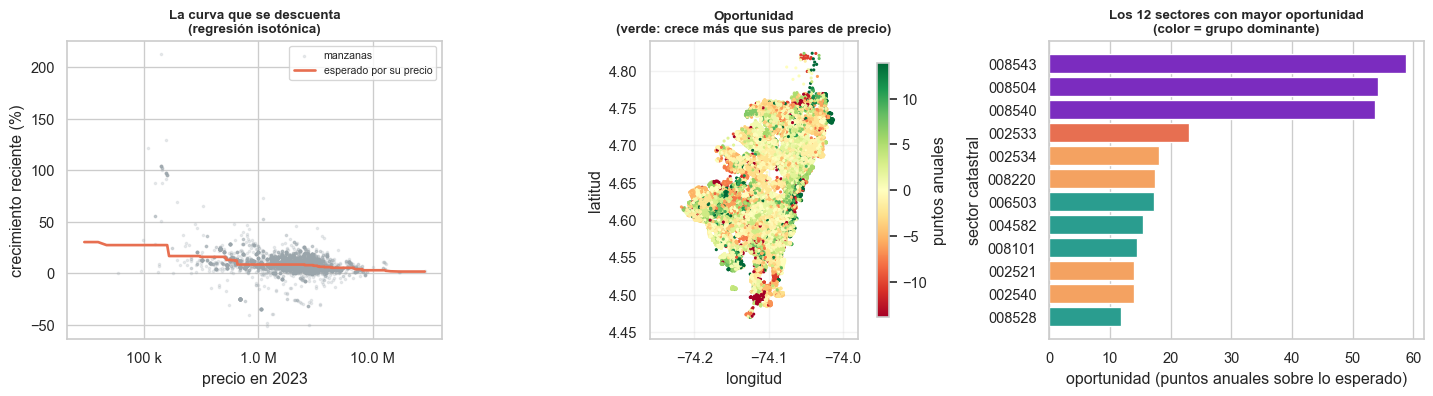

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))

o = datos.sample(min(8000, len(datos)), random_state=SEMILLA)
ax[0].scatter(10 ** o["nivel_inicio"], o["cagr_reciente"].map(pct), s=3, alpha=.2,
              color=GRIS, label="manzanas")
orden = datos.sort_values("nivel_inicio")
ax[0].plot(10 ** orden["nivel_inicio"], orden["esperado"].map(pct), color=ROJO, lw=2,
           label="esperado por su precio")
ax[0].set_xscale("log"); ax[0].xaxis.set_major_formatter(mticker.FuncFormatter(pesos))
ax[0].set_xlabel("precio en %d" % ANIO_RECIENTE)
ax[0].set_ylabel("crecimiento reciente (%)")
ax[0].set_title("La curva que se descuenta\n(regresión isotónica)"); ax[0].legend(fontsize=8)

d = datos[datos["lon"].between(*C.URB_LON) & datos["lat"].between(*C.URB_LAT)]
lim = np.nanpercentile(np.abs(d["oportunidad"].map(pct)), 96)
s = ax[1].scatter(d["lon"], d["lat"], c=d["oportunidad"].map(pct), s=1.8,
                  cmap="RdYlGn", vmin=-lim, vmax=lim)
formato_mapa(ax[1], "Oportunidad\n(verde: crece más que sus pares de precio)")
ax[1].set_ylabel("latitud")
plt.colorbar(s, ax=ax[1], label="puntos anuales", shrink=.85)

t = por_sector.sort_values("oportunidad_pct", ascending=False).head(12).iloc[::-1]
ax[2].barh([str(i) for i in t.index], t["oportunidad_pct"],
           color=[PALETA[int(c) % len(PALETA)] for c in t["cluster_dominante"]])
ax[2].set_xlabel("oportunidad (puntos anuales sobre lo esperado)")
ax[2].set_ylabel("sector catastral")
ax[2].set_title("Los 12 sectores con mayor oportunidad\n(color = grupo dominante)")
ax[2].grid(axis="y", alpha=0)

fig.tight_layout(); guardar_fig(fig, "clu_fig09_oportunidad.png"); plt.show()

### 7.2 Atípicas: las que no se parecen a nada

Tres detectores independientes, porque cada uno encuentra una rareza distinta:

- **Ruido de DBSCAN** — la manzana está en una región de baja densidad.
- **Verosimilitud baja en la mezcla gaussiana** — ninguna componente la explica.
- **Lejanía del centroide propio** — pertenece a un grupo pero mal.

Lo interesante no es cada lista por separado sino la **intersección**: una
manzana marcada por los tres no es un capricho del método.

In [24]:
datos["dbscan"] = db.labels_
datos["log_verosimilitud"] = gmm.score_samples(Z)
datos["dist_centroide"] = np.linalg.norm(Z - km.cluster_centers_[km.labels_], axis=1)

datos["at_ruido"] = datos["dbscan"] == -1
datos["at_verosimilitud"] = datos["log_verosimilitud"] < np.percentile(
    datos["log_verosimilitud"], PCT_ATIPICAS)
datos["at_lejania"] = datos["dist_centroide"] > np.percentile(
    datos["dist_centroide"], 100 - PCT_ATIPICAS)
datos["n_detectores"] = datos[["at_ruido", "at_verosimilitud", "at_lejania"]].sum(axis=1)

resumen_at = pd.DataFrame({
    "detector": ["ruido de DBSCAN", "verosimilitud baja (GMM)", "lejos de su centroide",
                 "al menos dos detectores", "los tres detectores"],
    "manzanas": [int(datos["at_ruido"].sum()), int(datos["at_verosimilitud"].sum()),
                 int(datos["at_lejania"].sum()), int((datos["n_detectores"] >= 2).sum()),
                 int((datos["n_detectores"] == 3).sum())],
})
resumen_at["pct"] = (100 * resumen_at["manzanas"] / len(datos)).round(2)
guardar_tabla(resumen_at, "t54_deteccion_atipicas.csv", index=False)
print("solapamiento entre detectores (por eso se exige coincidencia)\n")
resumen_at

solapamiento entre detectores (por eso se exige coincidencia)



,detector,manzanas,pct
0,ruido de DBSCAN,2209,5.9
1,verosimilitud baja (GMM),375,1.0
2,lejos de su centroide,375,1.0
3,al menos dos detectores,488,1.3
4,los tres detectores,262,0.7


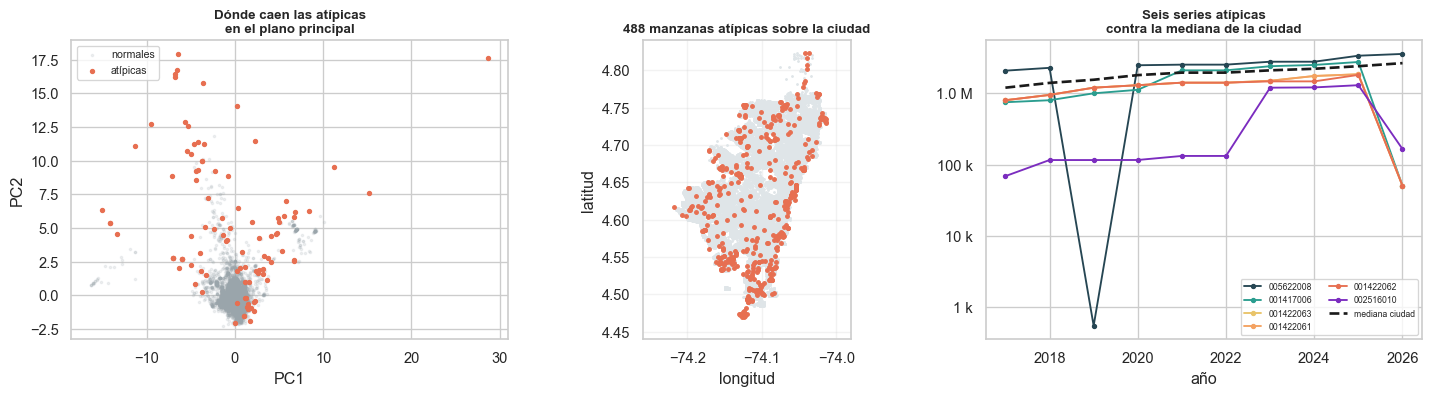

perfil de las atipicas frente al resto (mediana de cada rasgo):

               atipicas   resto  distancia_en_sigmas
nivel            6.0537  6.4502                -1.48
cagr_total       0.0369  0.0366                 0.02
cagr_reciente    0.0320  0.0340                -0.06
aceleracion      0.0031 -0.0013                 0.14
volatilidad      0.2487  0.0297                 3.63
inercia          0.1250  0.0000                 1.20
salto_max        0.5065  0.0934                 3.32
pron_relativo    0.0100  0.0000                 0.01


In [25]:
atipicas = datos[datos["n_detectores"] >= 2].copy()
comparativa = pd.DataFrame({
    "atipicas": atipicas[RASGOS].median(),
    "resto": datos[datos["n_detectores"] < 2][RASGOS].median(),
}).round(4)
# una razon entre medianas se vuelve absurda si el denominador es cero o cambia de
# signo: se reporta la distancia en desviaciones tipicas, que siempre se puede leer
desv = datos[RASGOS].std()
comparativa["distancia_en_sigmas"] = ((comparativa["atipicas"] - comparativa["resto"]) / desv).round(2)
guardar_tabla(comparativa, "t54b_perfil_atipicas.csv")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].scatter(P[sub, 0], P[sub, 1], s=3, alpha=.15, color=GRIS, label="normales")
m_at = datos["n_detectores"].values[sub] >= 2
ax[0].scatter(P[sub][m_at, 0], P[sub][m_at, 1], s=9, color=ROJO, label="atípicas")
ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2")
ax[0].set_title("Dónde caen las atípicas\nen el plano principal"); ax[0].legend(fontsize=8)

d = datos[datos["lon"].between(*C.URB_LON) & datos["lat"].between(*C.URB_LAT)]
ax[1].scatter(d["lon"], d["lat"], s=1.2, color="#dfe5e8")
da = d[d["n_detectores"] >= 2]
ax[1].scatter(da["lon"], da["lat"], s=7, color=ROJO)
formato_mapa(ax[1], "%d manzanas atípicas sobre la ciudad" % len(da))
ax[1].set_ylabel("latitud")

muestra_at = atipicas.nlargest(6, "dist_centroide")["manzana"]
for i, mz_id in enumerate(muestra_at):
    serie = 10 ** LOG.loc[mz_id]
    ax[2].plot(serie.index, serie.values, "o-", lw=1.4, ms=3,
               color=PALETA[i % len(PALETA)], label=mz_id)
ax[2].plot(ancha.columns, ancha.median(), "k--", lw=2, label="mediana ciudad")
ax[2].set_yscale("log"); ax[2].yaxis.set_major_formatter(mticker.FuncFormatter(pesos))
ax[2].set_xlabel("año"); ax[2].set_title("Seis series atípicas\ncontra la mediana de la ciudad")
ax[2].legend(fontsize=6.5, ncol=2)

fig.tight_layout(); guardar_fig(fig, "clu_fig10_atipicas.png"); plt.show()
print("perfil de las atipicas frente al resto (mediana de cada rasgo):\n")
print(comparativa.to_string())

### El archivo de salida

In [26]:
salida = datos[["manzana", "sector", "lon", "lat", "cop_m2_2026", "cluster",
                "nivel", "cagr_total", "cagr_reciente", "aceleracion", "volatilidad",
                "inercia", "salto_max", "pron_relativo",
                "oportunidad", "dist_centroide", "log_verosimilitud", "n_detectores"]].copy()
salida["nombre_cluster"] = salida["cluster"].map(nombres_cl)
salida["cluster_contiguo"] = ward_esp.labels_
salida["oportunidad_pct"] = salida["oportunidad"].map(pct).round(2)
salida["atipica"] = salida["n_detectores"] >= 2
salida.to_csv(F_SALIDA, index=False)
print("guardado: %s | %d manzanas, %d columnas" % (F_SALIDA.name, len(salida), salida.shape[1]))
print()
print("RESUMEN")
print("  %d grupos de comportamiento, elegidos por estabilidad (ARI %.3f)"
      % (K, indices.loc[K, "estabilidad_ari"]))
print("  pureza espacial %.3f frente a %.3f al azar: los grupos SI dibujan zonas"
      % (pureza_espacial(km.labels_), 1 / K))
print("  grupo con mayor oportunidad: %d (%s), %+.2f puntos sobre lo esperado"
      % (opor_cluster.index[0], opor_cluster.iloc[0]["nombre"], opor_cluster.iloc[0]["oportunidad_pct"]))
print("  %d manzanas atipicas (%.1f%%) marcadas por dos o mas detectores"
      % (int((datos["n_detectores"] >= 2).sum()), 100 * (datos["n_detectores"] >= 2).mean()))
salida.head()

guardado: clusters_manzanas.csv.gz | 37442 manzanas, 22 columnas

RESUMEN
  6 grupos de comportamiento, elegidos por estabilidad (ARI 0.466)
  pureza espacial 0.864 frente a 0.167 al azar: los grupos SI dibujan zonas
  grupo con mayor oportunidad: 5 (barato, acelerando e inestable), +58.75 puntos sobre lo esperado
  488 manzanas atipicas (1.3%) marcadas por dos o mas detectores


,manzana,sector,lon,lat,cop_m2_2026,cluster,nivel,cagr_total,cagr_reciente,aceleracion,...,salto_max,pron_relativo,oportunidad,dist_centroide,log_verosimilitud,n_detectores,nombre_cluster,cluster_contiguo,oportunidad_pct,atipica
0,005635004,005635,-74.115116,4.707818,3387000.0,1,6.529815,0.025421,0.027552,0.002132,...,0.044204,-0.17,-0.004987,0.821467,11.494723,0,"caro, al ritmo de la ciudad",5,-1.14,False
1,005635042,005635,-74.112751,4.707911,3474000.0,1,6.540830,0.026644,0.031224,0.004580,...,0.044204,-0.27,-0.001316,0.798399,11.182897,0,"caro, al ritmo de la ciudad",5,-0.30,False
2,006525027,006525,-74.168524,4.681705,1244000.0,4,6.094820,0.027747,0.020466,-0.007281,...,0.079181,-0.95,-0.014559,1.563083,-5.042892,0,"medio, al ritmo de la ciudad y quieto",5,-3.30,False
3,002527007,002527,-74.108267,4.511395,1400000.0,3,6.146128,0.049684,0.041646,-0.008038,...,0.096910,0.06,0.006621,0.760243,10.214917,0,"barato, al ritmo de la ciudad",2,1.54,False
4,002527014,002527,-74.107248,4.510175,1400000.0,3,6.146128,0.049684,0.041646,-0.008038,...,0.096910,0.05,0.006621,0.762320,10.194178,0,"barato, al ritmo de la ciudad",2,1.54,False


## 8. Síntesis

**Lo que se puede afirmar**

- Los grupos se formaron **sin mirar el mapa** y aun así dibujan zonas
  reconocibles, con una pureza espacial muy por encima del azar. Buena parte de
  eso viene de que Catastro valora por zonas homogéneas —manzanas vecinas
  comparten valor e historia por construcción— así que no es una validación
  independiente tan limpia como parece. Lo que sí queda establecido es que el
  grupo de una manzana predice su posición en el gradiente urbano: la distancia
  al eje financiero separa a los grupos casi tanto como lo haría una variable
  usada para construirlos.
- La **estabilidad por remuestreo** es el único criterio que distingue una
  estructura real de un corte arbitrario, y rara vez señala el mismo k que la
  silueta o el BIC. Cuando discrepan, los índices geométricos suelen estar
  describiendo la forma de la nube, no la existencia de grupos.
- **La oportunidad no es el crecimiento.** Al descontar la reversión a la media,
  la lista de zonas deja de ser un ranking de pobreza y pasa a señalar sitios
  que se mueven distinto a sus pares de precio. Es la lista que sirve para
  decidir.
- Las **atípicas** marcadas por dos o más detectores son pocas y vale la pena
  mirarlas una a una: la mayoría son saltos administrativos bruscos, que es
  información sobre el proceso de Catastro tanto como sobre el mercado.

**Lo que hay que tener presente**

- El insumo sigue siendo `V_REF`, un valor administrativo. Un cluster "quieto"
  puede ser un mercado estancado o una zona que Catastro no ha revisado.
- `pron_relativo` viene de un modelo cuya señal dominante era el nivel de
  precio, así que refuerza un eje que ya estaba. Quitarlo de `RASGOS` y volver a
  correr es un experimento de una línea.
- Los nombres de los grupos los pone una regla automática sobre el perfil
  estandarizado. Son una ayuda de lectura, no una clasificación oficial.
- Todo es por manzana y en pesos nominales.

**Qué haría falta para ir más lejos**

Los clusters describen *cómo* se comporta cada zona, no *por qué*. Licencias de
construcción, planes parciales, obra nueva y cambios de norma son las variables
que explicarían las diferencias entre grupos —y son justamente las que no están
en estos servicios públicos.